In [3]:
# Imports

import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import TwoSlopeNorm
import cartopy.mpl.ticker as cticker


## Plot oxygen trend over common period

Using symmetric color range ±0.618


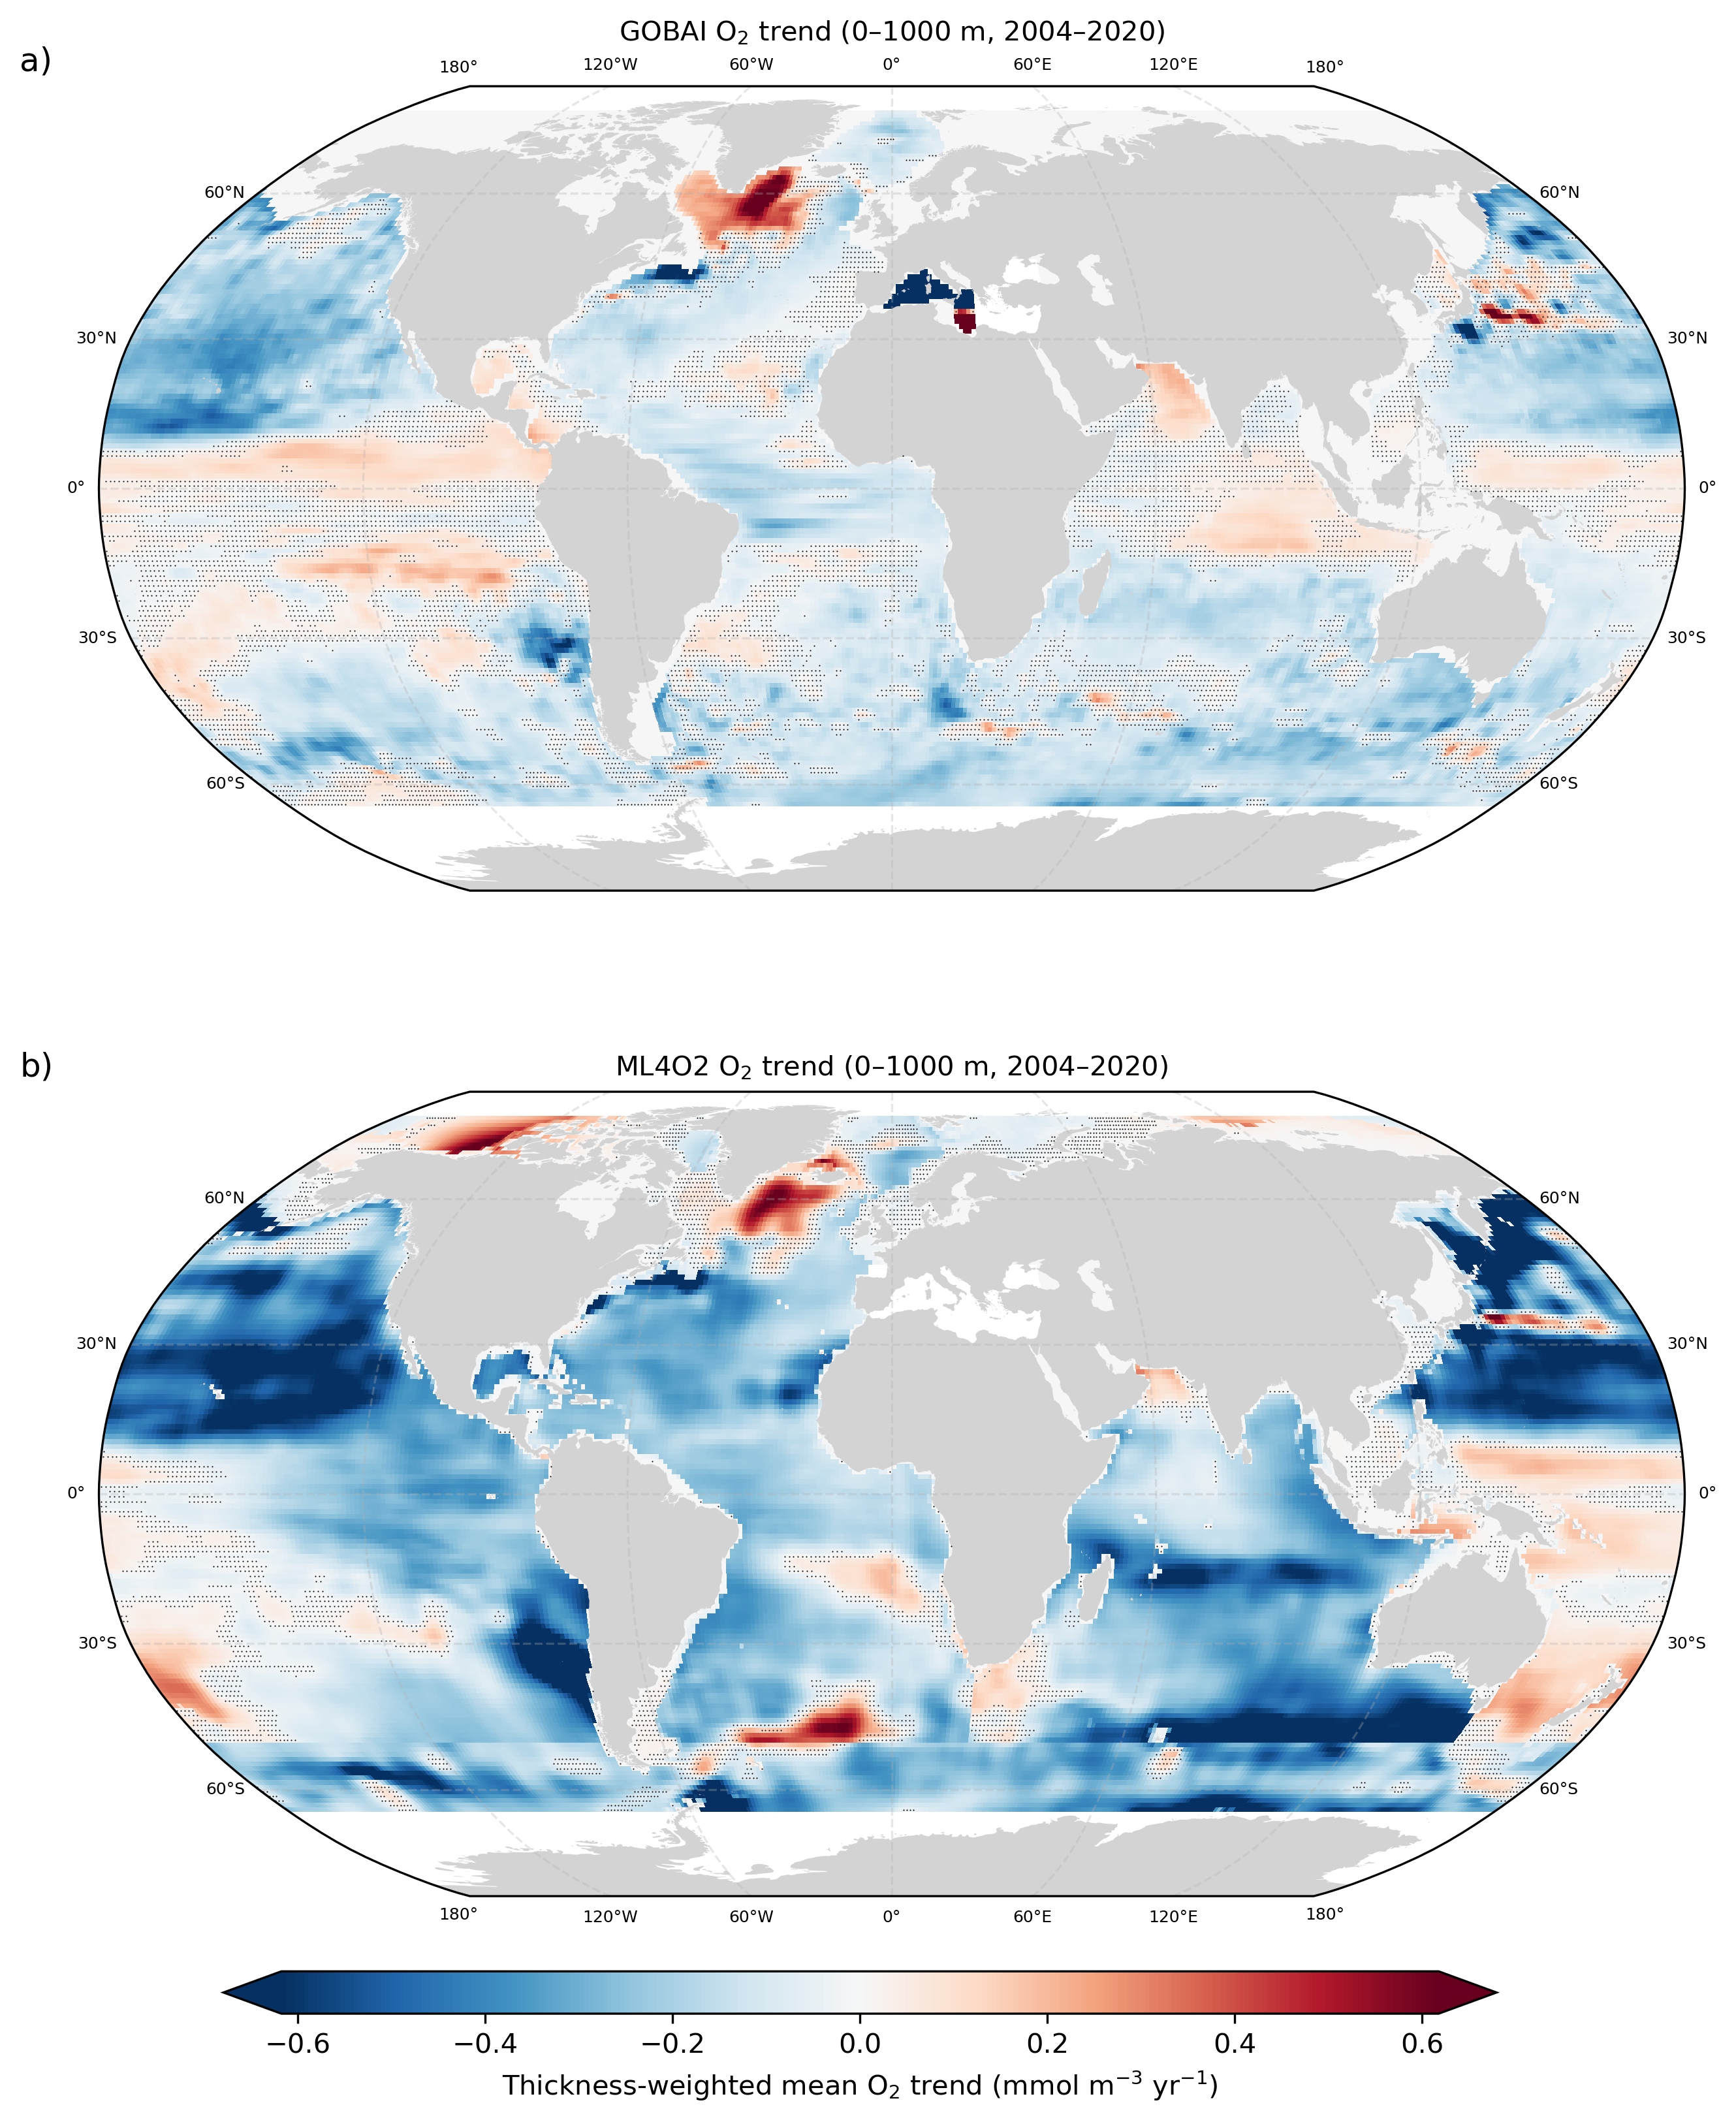

Saved: figs/FigS_A_GOBAI_vs_ML4O2_trends_with_nonsig_stippling.png


In [4]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker

from matplotlib.colors import TwoSlopeNorm
from scipy.stats import t as student_t

# ============================================================
# SETTINGS
# ============================================================
TIME0 = "2004-01-01"
TIME1 = "2020-12-31"
ZMIN  = 0
ZMAX  = 1000

PLOT_WHAT = "mean"   # "mean" recommended
PCTL = 98            # robust symmetric color scaling percentile

PVAL_ALPHA = 0.05
ZERO_TREND_TOL = 1e-12

STIPPLE_SIZE = 1.0
STIPPLE_COLOR = "black"

OUTPATH = "figs/FigS_A_GOBAI_vs_ML4O2_trends_with_nonsig_stippling.png"

# ============================================================
# HELPERS
# ============================================================
def mask_mediterranean(lat, lon):
    return (lat >= 30) & (lat <= 46) & (lon >= -6) & (lon <= 37)

def slope_and_se_1d(y, tvec):
    """
    Regression of y against tvec.
    Returns slope, standard error of slope, p-value.
    """
    y = np.asarray(y, dtype=float)
    tvec = np.asarray(tvec, dtype=float)

    m = np.isfinite(y) & np.isfinite(tvec)
    n = int(m.sum())
    if n < 3:
        return np.nan, np.nan, np.nan

    yy = y[m]
    tt = tvec[m]

    tbar = tt.mean()
    ybar = yy.mean()

    tt_c = tt - tbar
    yy_c = yy - ybar

    sxx = np.sum(tt_c**2)
    if sxx <= 0 or not np.isfinite(sxx):
        return np.nan, np.nan, np.nan

    slope = np.sum(tt_c * yy_c) / sxx
    intercept = ybar - slope * tbar

    yhat = intercept + slope * tt
    resid = yy - yhat

    df = n - 2
    if df <= 0:
        return slope, np.nan, np.nan

    s2 = np.sum(resid**2) / df
    se_slope = np.sqrt(s2 / sxx)

    if not np.isfinite(se_slope) or se_slope == 0:
        return slope, se_slope, np.nan

    tstat = slope / se_slope
    pval = 2.0 * student_t.sf(np.abs(tstat), df)

    return slope, se_slope, pval

# ============================================================
# LOAD DATA
# ============================================================
ds  = xr.load_dataset("data/CONTENT_DIC_v2-3.nc")          # GOBAI-like
ito = xr.load_dataset("data/o2_NN_ship+Argo_ensmean.nc")   # ML4O2

# ============================================================
# GOBAI: trend field over 0-1000 dbar
# ============================================================
g = ds.sel(time=slice(TIME0, TIME1)).sel(pres=slice(ZMIN, ZMAX))

t_year_g = ((g["time"] - g["time"].isel(time=0)) / np.timedelta64(1, "D")) / 365.25
g = g.assign_coords(t_year=("time", t_year_g.data))

fit_g = g["oxy"].polyfit(dim="t_year", deg=1, skipna=True)
o2_trend_g = fit_g["polyfit_coefficients"].sel(degree=1)  # per year at each depth

dp = g["pres"].diff("pres").reindex(pres=g["pres"], method=None).fillna(0)
dp = dp.broadcast_like(o2_trend_g)

o2_meantrend_gobai = ((o2_trend_g * dp).sum("pres", skipna=True) / dp.sum("pres")).rename("O2_meantrend_gobai")

# thickness-weighted mean O2 time series for significance
o2bar_g_t = (g["oxy"] * dp).sum("pres", skipna=True) / dp.sum("pres")
tg = g["t_year"].values.astype(float)

_, se_g, pval_g = xr.apply_ufunc(
    slope_and_se_1d,
    o2bar_g_t,
    xr.DataArray(tg, dims=("time",), coords={"time": o2bar_g_t["time"]}),
    input_core_dims=[["time"], ["time"]],
    output_core_dims=[[], [], []],
    vectorize=True,
    dask="parallelized",
    output_dtypes=[float, float, float],
)

# ============================================================
# ML4O2: trend field over 0-1000 m
# ============================================================
i = ito.sel(time=slice(TIME0, TIME1)).sel(depth=slice(ZMIN, ZMAX))

t_year_i = ((i["time"] - i["time"].isel(time=0)) / np.timedelta64(1, "D")) / 365.25
i = i.assign_coords(t_year=("time", t_year_i.data))

fit_i = i["o2"].polyfit(dim="t_year", deg=1, skipna=True)
o2_trend_i = fit_i["polyfit_coefficients"].sel(degree=1)

dz = i["depth"].diff("depth").reindex(depth=i["depth"], method=None).fillna(0)
dz = dz.broadcast_like(o2_trend_i)

o2_meantrend_ito = ((o2_trend_i * dz).sum("depth", skipna=True) / dz.sum("depth")).rename("O2_meantrend_ito")

# thickness-weighted mean O2 time series for significance
o2bar_i_t = (i["o2"] * dz).sum("depth", skipna=True) / dz.sum("depth")
ti = i["t_year"].values.astype(float)

_, se_i, pval_i = xr.apply_ufunc(
    slope_and_se_1d,
    o2bar_i_t,
    xr.DataArray(ti, dims=("time",), coords={"time": o2bar_i_t["time"]}),
    input_core_dims=[["time"], ["time"]],
    output_core_dims=[[], [], []],
    vectorize=True,
    dask="parallelized",
    output_dtypes=[float, float, float],
)

# ============================================================
# PREPARE PLOTTING FIELDS
# ============================================================
gobai_2d = o2_meantrend_gobai.transpose("lat", "lon")
ito_2d   = o2_meantrend_ito.transpose("lat", "lon")

lat_g = gobai_2d["lat"].values
ito_2d = ito_2d.sel(lat=slice(lat_g.min(), lat_g.max()))

pval_g = pval_g.transpose("lat", "lon")
pval_i = pval_i.transpose("lat", "lon").sel(lat=slice(lat_g.min(), lat_g.max()))

# Mediterranean mask
lat2d_g, lon2d_g = xr.broadcast(gobai_2d["lat"], gobai_2d["lon"])
lat2d_i, lon2d_i = xr.broadcast(ito_2d["lat"], ito_2d["lon"])

med_g = mask_mediterranean(lat2d_g, lon2d_g)
med_i = mask_mediterranean(lat2d_i, lon2d_i)

gobai_2d = gobai_2d.where(~med_g)
ito_2d   = ito_2d.where(~med_i)

pval_g = pval_g.where(~med_g).where(np.isfinite(gobai_2d))
pval_i = pval_i.where(~med_i).where(np.isfinite(ito_2d))

# non-significant stippling masks, excluding zero-trend cells
nonsig_g = (pval_g >= PVAL_ALPHA) & (np.abs(gobai_2d) > ZERO_TREND_TOL)
nonsig_i = (pval_i >= PVAL_ALPHA) & (np.abs(ito_2d) > ZERO_TREND_TOL)

# Convert to numpy
gobai_map = gobai_2d.values
ito_map   = ito_2d.values

# shared robust symmetric color scale
allvals = np.concatenate([gobai_map.ravel(), ito_map.ravel()])
allvals = allvals[np.isfinite(allvals)]
v = np.nanpercentile(np.abs(allvals), PCTL)
norm = TwoSlopeNorm(vcenter=0.0, vmin=-v, vmax=v)

print(f"Using symmetric color range ±{v:.3f}")

# ============================================================
# PLOT
# ============================================================
fig = plt.figure(figsize=(13, 12), dpi=300)

land = cfeature.NaturalEarthFeature(
    "physical", "land", "50m",
    edgecolor="none", facecolor="lightgrey"
)

# ----------------------------
# Panel a: GOBAI
# ----------------------------
ax1 = fig.add_subplot(2, 1, 1, projection=ccrs.Robinson())
ax1.set_global()
ax1.add_feature(land)
ax1.text(-0.05, 1.05, "a)", transform=ax1.transAxes, fontsize=12, va="top")

gl1 = ax1.gridlines(draw_labels=True, alpha=0.3, linestyle="--")
gl1.top_labels = True
gl1.bottom_labels = False
gl1.left_labels = True
gl1.right_labels = True
gl1.xformatter = cticker.LongitudeFormatter()
gl1.yformatter = cticker.LatitudeFormatter()

fig.canvas.draw()
for lbl in gl1.xlabel_artists + gl1.ylabel_artists:
    lbl.set_fontsize(6)

im1 = ax1.pcolormesh(
    lon2d_g.values, lat2d_g.values, gobai_map,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r", norm=norm, shading="auto"
)

ax1.scatter(
    lon2d_g.values[nonsig_g.values],
    lat2d_g.values[nonsig_g.values],
    s=STIPPLE_SIZE,
    c=STIPPLE_COLOR,
    marker=".",
    linewidths=0,
    alpha=1.0,
    transform=ccrs.PlateCarree(),
    zorder=4,
)

ax1.set_title(
    f"GOBAI O$_2$ trend (0–1000 m, {TIME0[:4]}–{TIME1[:4]})",
    fontsize=10
)

# ----------------------------
# Panel b: ML4O2
# ----------------------------
ax2 = fig.add_subplot(2, 1, 2, projection=ccrs.Robinson())
ax2.set_global()
ax2.add_feature(land)
ax2.text(-0.05, 1.05, "b)", transform=ax2.transAxes, fontsize=12, va="top")

gl2 = ax2.gridlines(draw_labels=True, alpha=0.3, linestyle="--")
gl2.top_labels = False
gl2.bottom_labels = True
gl2.left_labels = True
gl2.right_labels = True
gl2.xformatter = cticker.LongitudeFormatter()
gl2.yformatter = cticker.LatitudeFormatter()

fig.canvas.draw()
for lbl in gl2.xlabel_artists + gl2.ylabel_artists:
    lbl.set_fontsize(6)

im2 = ax2.pcolormesh(
    lon2d_i.values, lat2d_i.values, ito_map,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r", norm=norm, shading="auto"
)

ax2.scatter(
    lon2d_i.values[nonsig_i.values],
    lat2d_i.values[nonsig_i.values],
    s=STIPPLE_SIZE,
    c=STIPPLE_COLOR,
    marker=".",
    linewidths=0,
    alpha=1.0,
    transform=ccrs.PlateCarree(),
    zorder=4,
)

ax2.set_title(
    f"ML4O2 O$_2$ trend (0–1000 m, {TIME0[:4]}–{TIME1[:4]})",
    fontsize=10
)

# Shared colorbar
cax = fig.add_axes([0.25, 0.06, 0.5, 0.018])
cbar = fig.colorbar(im1, cax=cax, orientation="horizontal", extend="both")
cbar.set_label(r"Thickness-weighted mean O$_2$ trend (mmol m$^{-3}$ yr$^{-1}$)")

plt.subplots_adjust(hspace=0.25)
fig.savefig(OUTPATH, bbox_inches="tight", dpi=300)
plt.show()

print("Saved:", OUTPATH)

Valid pixels: 49028
Sign disagreement pixels: 7405
Fraction disagreement: 15.10%
Red pixels (disagree + GOBAI significant): 3875 (52.33%)
Black pixels (disagree + GOBAI not significant): 3530 (47.67%)


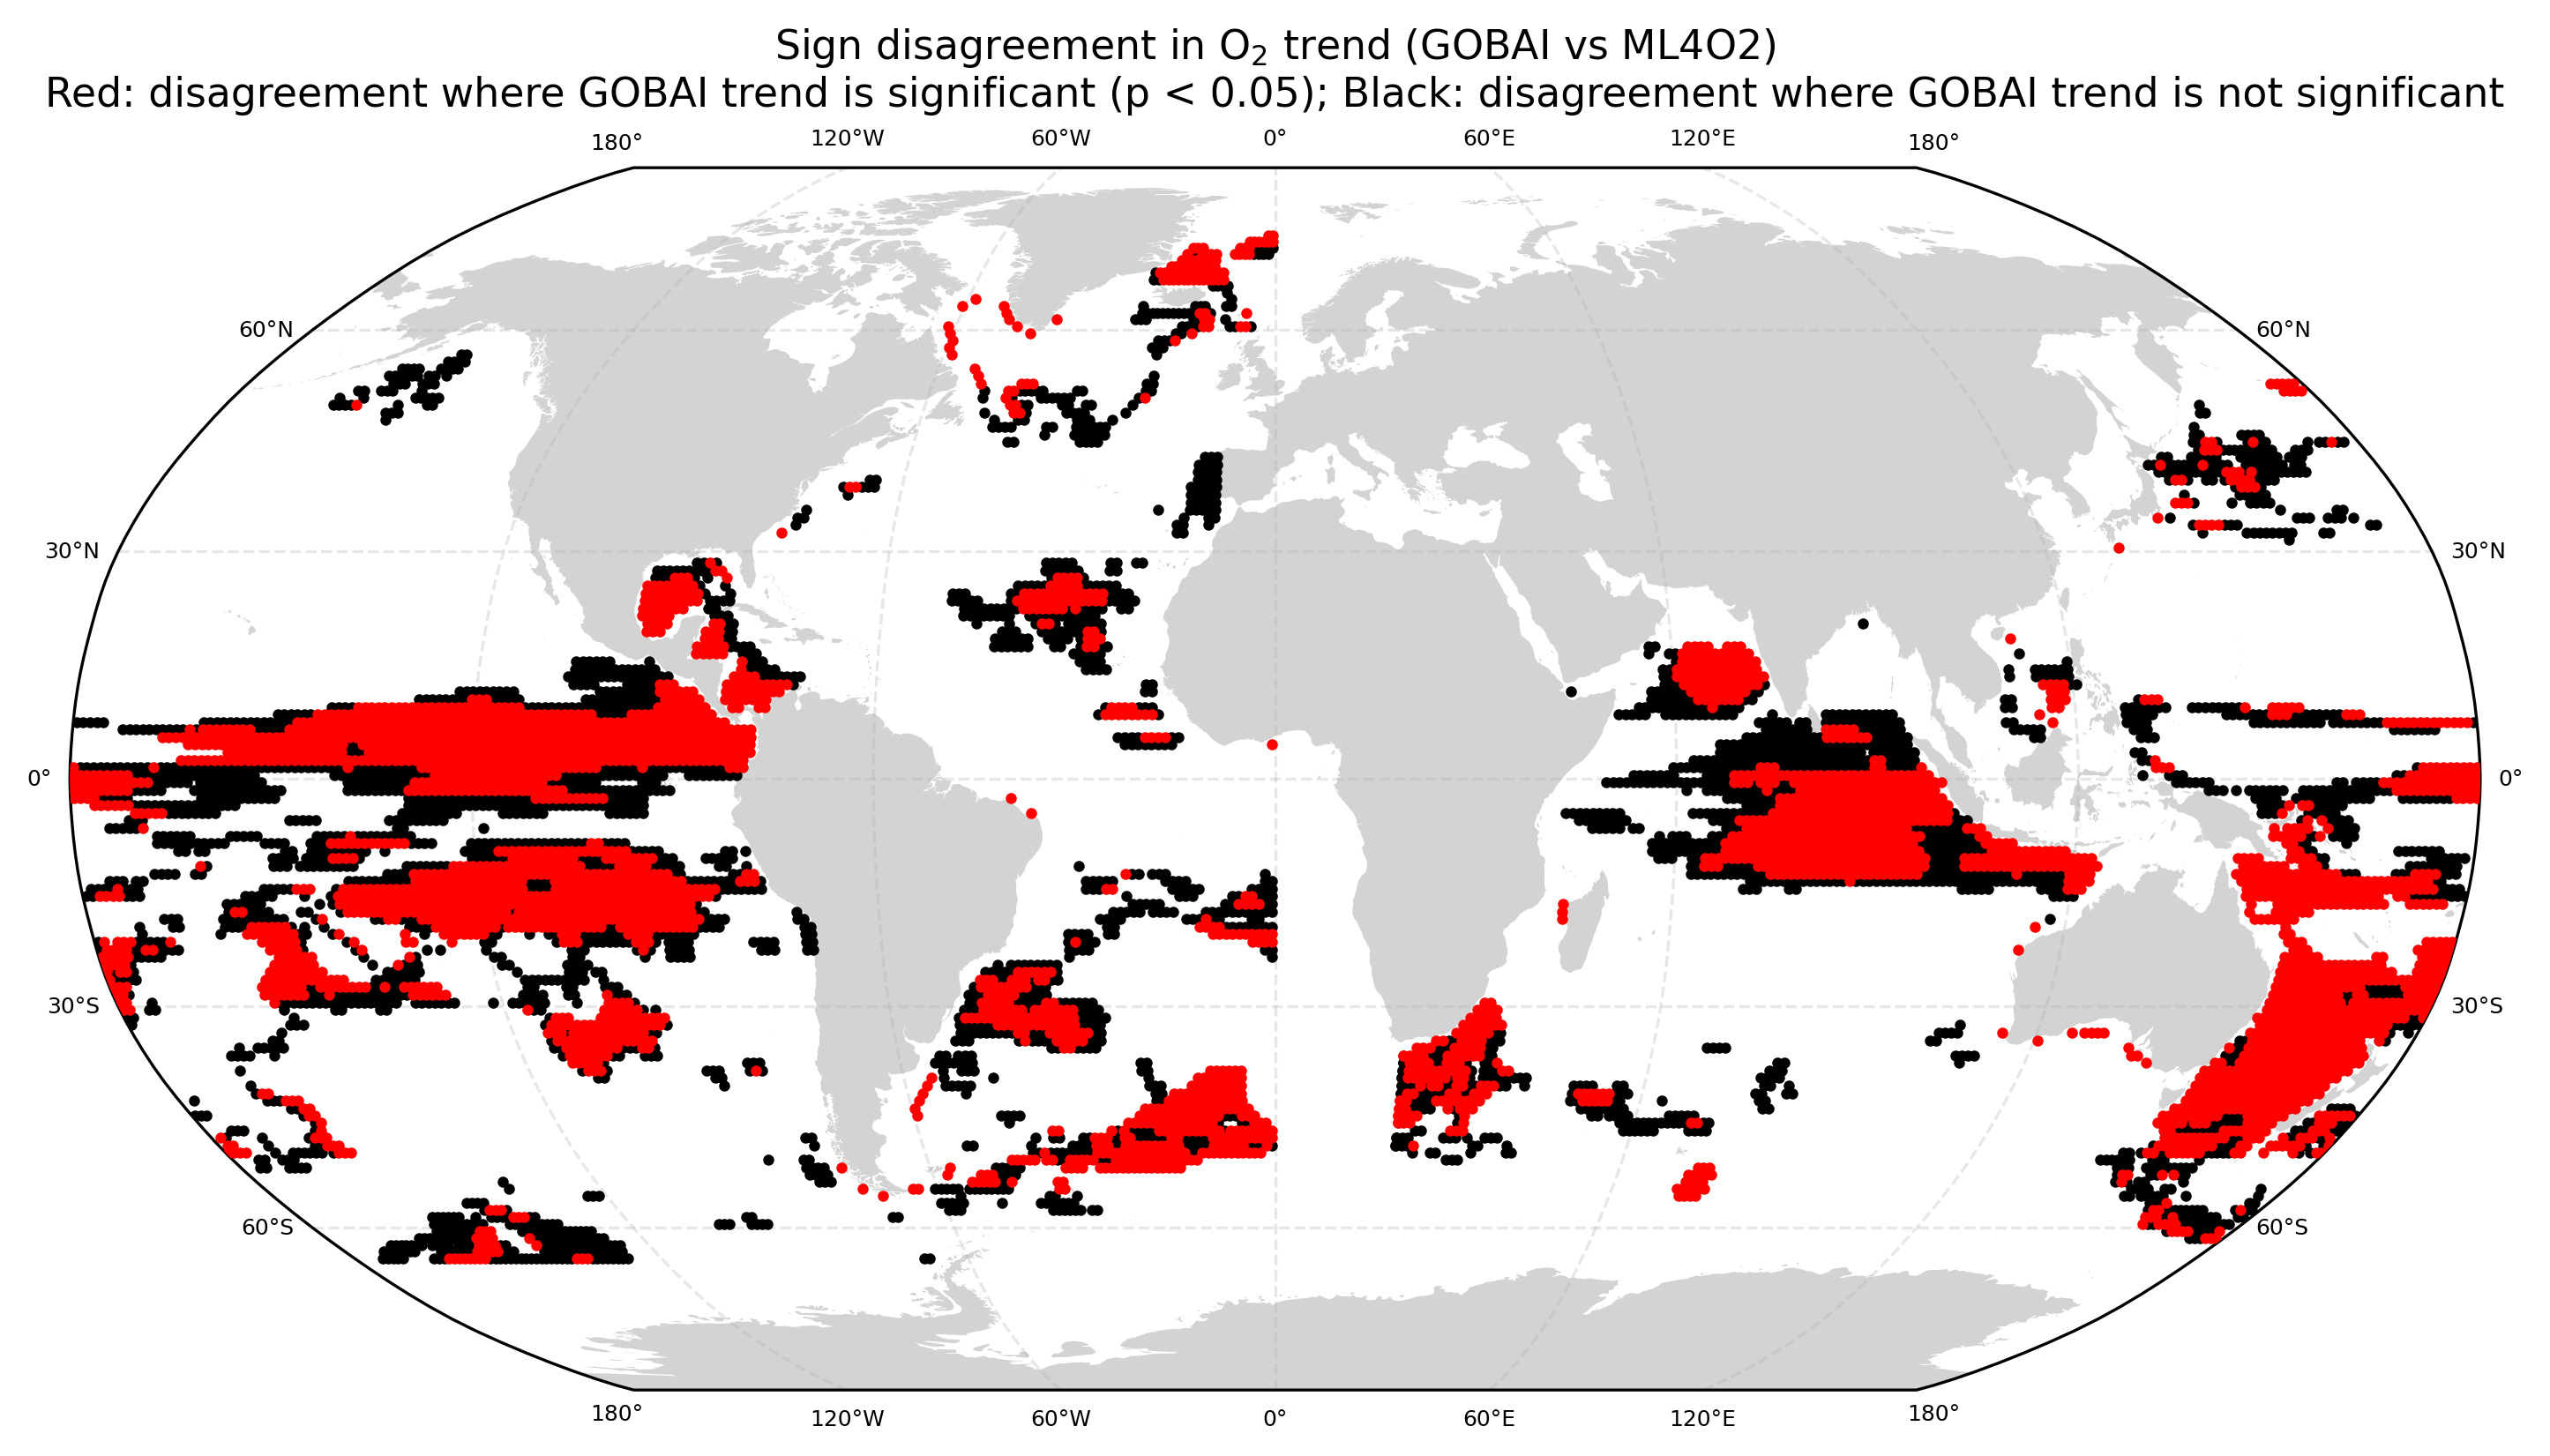

Saved: figs/FigS_B_O2_sign_disagreement_GOBAI_significance.png


In [5]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
from cartopy.util import add_cyclic_point

# ============================================================
# SETTINGS
# ============================================================
DOTSIZE = 4
OUTPATH = "figs/FigS_B_O2_sign_disagreement_GOBAI_significance.png"

# ============================================================
# REQUIRED INPUTS ALREADY IN MEMORY
# ------------------------------------------------------------
# o2_meantrend_gobai : GOBAI thickness-weighted mean O2 trend
# o2_meantrend_ito   : ML4O2 thickness-weighted mean O2 trend
# pval_g             : GOBAI p-value field for local O2 trend
# mask_mediterranean : function(lat, lon) -> boolean mask
# ============================================================

# ============================================================
# PUT ML4O2 ON SAME LONGITUDE CONVENTION AS GOBAI
# GOBAI: 0–360
# ML4O2: shift from -180–180 to 0–360
# ============================================================
o2_meantrend_ito_shifted = o2_meantrend_ito.assign_coords(
    lon=((o2_meantrend_ito["lon"] + 360) % 360)
).sortby("lon")

# ============================================================
# INTERPOLATE ML4O2 ONTO GOBAI GRID
# ============================================================
ito_on_gobai = o2_meantrend_ito_shifted.interp(
    lat=o2_meantrend_gobai["lat"],
    lon=o2_meantrend_gobai["lon"],
    method="linear"
)

# ============================================================
# MATCH DIMENSIONS
# ============================================================
gtrend = o2_meantrend_gobai.transpose("lat", "lon")
itrend = ito_on_gobai.transpose("lat", "lon")
pval_g = pval_g.transpose("lat", "lon")

# ============================================================
# APPLY MEDITERRANEAN MASK
# ============================================================
lat2d, lon2d = xr.broadcast(gtrend["lat"], gtrend["lon"])
med = mask_mediterranean(lat2d, lon2d)

gtrend = gtrend.where(~med)
itrend = itrend.where(~med)
pval_g = pval_g.where(~med)

# ============================================================
# VALID PIXELS
# ============================================================
valid = np.isfinite(gtrend) & np.isfinite(itrend)

# Opposite sign only
sign_disagree = ((np.sign(gtrend) * np.sign(itrend)) < 0) & valid

# GOBAI significance
gobai_sig = (pval_g < 0.05) & valid

# ------------------------------------------------------------
# Final plotting masks
# black = disagreement where GOBAI is NOT significant
# red   = disagreement where GOBAI IS significant
# ------------------------------------------------------------
mask_red = sign_disagree & gobai_sig
mask_black = sign_disagree & (~gobai_sig)

# ============================================================
# DIAGNOSTICS
# ============================================================
n_valid = int(valid.sum())
n_disagree = int(sign_disagree.sum())
n_red = int(mask_red.sum())
n_black = int(mask_black.sum())

print(f"Valid pixels: {n_valid}")
print(f"Sign disagreement pixels: {n_disagree}")

if n_valid > 0:
    print(f"Fraction disagreement: {100 * n_disagree / n_valid:.2f}%")

if n_disagree > 0:
    print(f"Red pixels (disagree + GOBAI significant): {n_red} ({100 * n_red / n_disagree:.2f}%)")
    print(f"Black pixels (disagree + GOBAI not significant): {n_black} ({100 * n_black / n_disagree:.2f}%)")

# ============================================================
# ADD CYCLIC POINT FOR CLEAN GLOBAL PLOTTING
# ============================================================
lon_vals = gtrend["lon"].values
lat_vals = gtrend["lat"].values

mask_red_cyc, lon_cyc = add_cyclic_point(mask_red.values.astype(float), coord=lon_vals, axis=1)
mask_black_cyc, _ = add_cyclic_point(mask_black.values.astype(float), coord=lon_vals, axis=1)

lon2d_cyc, lat2d_cyc = np.meshgrid(lon_cyc, lat_vals)

mask_red_cyc = mask_red_cyc.astype(bool)
mask_black_cyc = mask_black_cyc.astype(bool)

# ============================================================
# PLOT
# ============================================================
fig = plt.figure(figsize=(12, 6), dpi=300)
ax = fig.add_subplot(1, 1, 1, projection=ccrs.Robinson())
ax.set_global()

land = cfeature.NaturalEarthFeature(
    "physical", "land", "50m",
    edgecolor="none", facecolor="lightgrey"
)
ax.add_feature(land)

gl = ax.gridlines(draw_labels=True, alpha=0.3, linestyle="--")
gl.top_labels = True
gl.bottom_labels = True
gl.left_labels = True
gl.right_labels = True
gl.xformatter = cticker.LongitudeFormatter()
gl.yformatter = cticker.LatitudeFormatter()

fig.canvas.draw()
for lbl in gl.xlabel_artists + gl.ylabel_artists:
    lbl.set_fontsize(6)

# Black = sign disagreement, GOBAI not significant
ax.scatter(
    lon2d_cyc[mask_black_cyc],
    lat2d_cyc[mask_black_cyc],
    s=DOTSIZE,
    color="black",
    transform=ccrs.PlateCarree(),
    zorder=4,
)

# Red = sign disagreement, GOBAI significant
ax.scatter(
    lon2d_cyc[mask_red_cyc],
    lat2d_cyc[mask_red_cyc],
    s=DOTSIZE,
    color="red",
    transform=ccrs.PlateCarree(),
    zorder=5,
)

ax.set_title(
    "Sign disagreement in O$_2$ trend (GOBAI vs ML4O2)\n"
    "Red: disagreement where GOBAI trend is significant (p < 0.05); "
    "Black: disagreement where GOBAI trend is not significant",
    fontsize=11
)

fig.savefig(OUTPATH, bbox_inches="tight", dpi=300)
plt.show()

print("Saved:", OUTPATH)

Loading GOBAI 0-1250 dbar...
Level 1/20: 6 m
Level 2/20: 10 m
Level 3/20: 20 m
Level 4/20: 30 m
Level 5/20: 40 m
Level 6/20: 50 m
Level 7/20: 65 m
Level 8/20: 80 m
Level 9/20: 100 m
Level 10/20: 150 m
Level 11/20: 200 m
Level 12/20: 250 m
Level 13/20: 300 m
Level 14/20: 400 m
Level 15/20: 500 m
Level 16/20: 600 m
Level 17/20: 700 m
Level 18/20: 800 m
Level 19/20: 900 m
Level 20/20: 1000 m


/var/folders/1v/4n_5d4_513x1v4s59v9zf9d80000gp/T/ipykernel_92244/2213520437.py:65: RuntimeWarning: Mean of empty slice
  dt = tt - np.nanmean(tt, 0)
/var/folders/1v/4n_5d4_513x1v4s59v9zf9d80000gp/T/ipykernel_92244/2213520437.py:66: RuntimeWarning: Mean of empty slice
  ybar = np.nanmean(y, 0)
/var/folders/1v/4n_5d4_513x1v4s59v9zf9d80000gp/T/ipykernel_92244/2213520437.py:65: RuntimeWarning: Mean of empty slice
  dt = tt - np.nanmean(tt, 0)
/var/folders/1v/4n_5d4_513x1v4s59v9zf9d80000gp/T/ipykernel_92244/2213520437.py:66: RuntimeWarning: Mean of empty slice
  ybar = np.nanmean(y, 0)


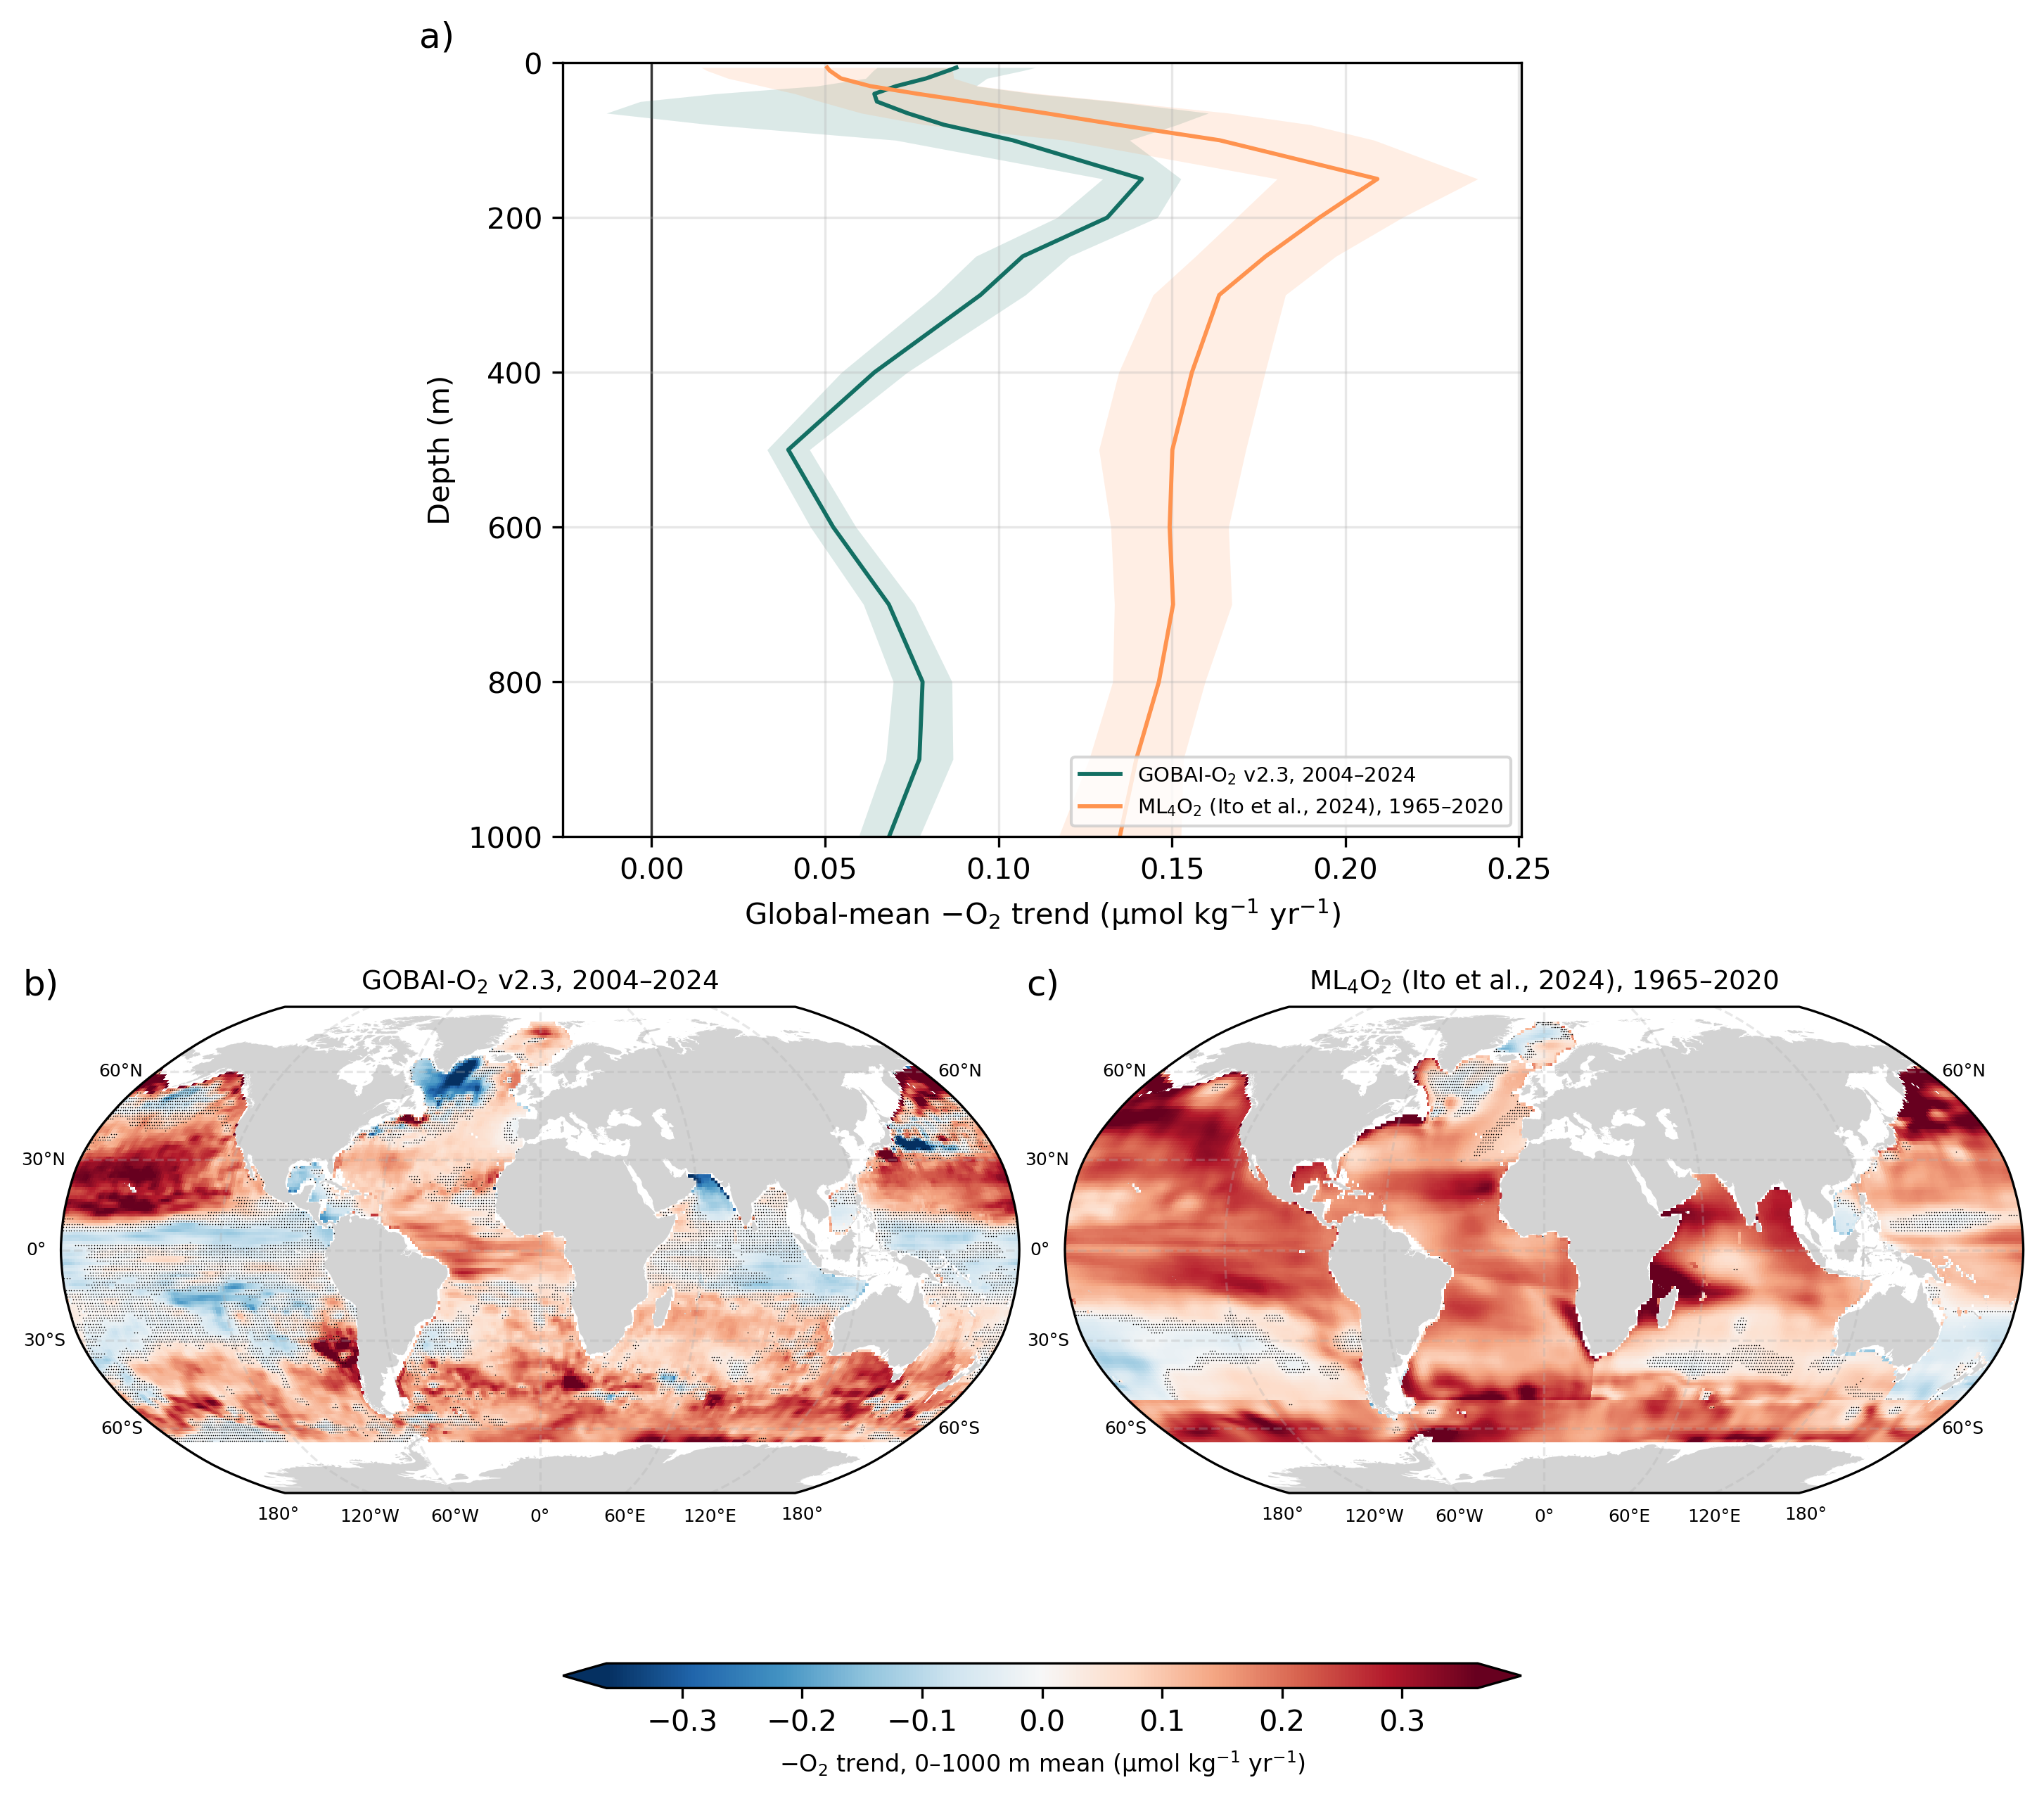

Saved: figs/FigS_O2_trend_detectability.png
GOBAI-O2 -O2, 2004-2024      0-1000 m +0.078 ± 0.007   100-1000 m +0.078   300-1000 m +0.067   (umol kg-1 yr-1, ±1 SE)
GOBAI-O2 AOU, 2004-2024      0-1000 m +0.047 ± 0.009   100-1000 m +0.052   300-1000 m +0.046   (umol kg-1 yr-1, ±1 SE)
ML4O2 -O2, 1965-2020         0-1000 m +0.151 ± 0.011   100-1000 m +0.157   300-1000 m +0.149   (umol kg-1 yr-1, ±1 SE)
ML4O2 -O2, 2004-2020         0-1000 m +0.236 ± 0.012   100-1000 m +0.240   300-1000 m +0.226   (umol kg-1 yr-1, ±1 SE)


In [2]:
# ============================================================
# TREND DETECTABILITY FIGURE (Reviewer 1, SI)
#   a) global-mean -O2 trend profiles, 0-1000 m: GOBAI-O2 v2.3 (2004-2024) and
#      ML4O2 (Ito et al., 2024; 1965-2020)
#   b) map: GOBAI-O2 v2.3 -O2 trend, 0-1000 m mean, 2004-2024
#   c) map: ML4O2 -O2 trend, 0-1000 m mean, 1965-2020
# The ML4O2 2004-2020 trend is printed only (Text S1), not plotted.
# ML4O2 provides O2 only (no T/S), so AOU cannot be computed for it. Both
# products are therefore compared as -O2 (AOU proxy). GOBAI AOU is computed
# only to print how close its AOU and -O2 trends are.
# Both products on the GOBAI grid and ML4O2 depth levels, over a common
# footprint (Mediterranean excluded). Trends: deseasonalised OLS; shading
# (±2 SE) and stippling (p >= 0.05) use lag-1 autocorrelation-adjusted SE.
# ============================================================

import numpy as np
import xarray as xr
import gsw
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.mpl.ticker as cticker
from matplotlib.colors import TwoSlopeNorm
from scipy.stats import t as student_t

try:
    import koolstof as ks
    ks.parameterisations.aou_GG92
    HAVE_KS = True
except (ImportError, AttributeError):
    HAVE_KS = False

# ---------------- settings ----------------
GOBAI_FILE = "data/CONTENT_DIC_v2-3.nc"
ITO_FILE   = "data/o2_NN_ship+Argo_ensmean.nc"
OUT_FIG    = "figs/FigS_O2_trend_detectability.png"
P_GOBAI = ("2004-01-01", "2024-12-31")
P_ITO   = ("1965-01-01", "2020-12-31")
P_OVERLAP = ("2004-01-01", "2020-12-31")   # common period, printed only
ZMAX = 1000
MIN_VALID_FRAC = 0.9
PVAL_ALPHA = 0.05
C_GOBAI, C_ITO = "#136F63", "#FF934F"

# ---------------- helpers ----------------
def mask_mediterranean(lat, lon):
    lon180 = ((lon + 180) % 360) - 180
    return (lat >= 30) & (lat <= 46) & (lon180 >= -6) & (lon180 <= 37)

def deseason(da):
    return da.groupby("time.month") - da.groupby("time.month").mean("time")

def t_years(da):
    return ((da["time"] - da["time"].isel(time=0)) / np.timedelta64(1, "D")).values / 365.25

def trend_ar1(y, t):
    """OLS trend along axis 0, SE adjusted for lag-1 autocorrelation (NaN-aware)."""
    y = np.asarray(y, dtype=float)
    t = np.asarray(t, dtype=float).reshape((-1,) + (1,) * (y.ndim - 1))
    m = np.isfinite(y)
    n = m.sum(0).astype(float)
    tt = np.where(m, t, np.nan)
    with np.errstate(invalid="ignore", divide="ignore"):
        dt = tt - np.nanmean(tt, 0)
        ybar = np.nanmean(y, 0)
        sxx = np.nansum(dt ** 2, 0)
        slope = np.nansum(dt * (y - ybar), 0) / sxx
        resid = y - ybar - slope * dt
        r1 = np.clip(np.nansum(resid[1:] * resid[:-1], 0) / np.nansum(resid ** 2, 0), 0, 0.99)
        neff = np.maximum(n * (1 - r1) / (1 + r1), 3.0)
        se = np.sqrt(np.nansum(resid ** 2, 0) / (n - 2) / sxx * (n - 2) / (neff - 2))
        p = 2 * student_t.sf(np.abs(slope / se), neff - 2)
    bad = n < 24
    return tuple(np.where(bad, np.nan, a) for a in (slope, se, p))

def o2sat(T, SP, p, lon, lat):
    """O2 solubility (umol kg-1), Garcia & Gordon (1992), as in 01A."""
    SA = gsw.SA_from_SP(SP, p, lon, lat)
    theta = gsw.pt0_from_t(SA, T, p)
    if HAVE_KS:
        return ks.parameterisations.aou_GG92(oxygen=0 * T, temperature=theta, salinity=SP)[0]
    return gsw.O2sol_SP_pt(SP, theta)

# ---------------- load ----------------
print("Loading GOBAI 0-1250 dbar...")
gob = xr.open_dataset(GOBAI_FILE)
g = gob[["oxy", "temp", "sal"]].sel(pres=slice(0, ZMAX * 1.25), time=slice(*P_GOBAI))
g = g.transpose("time", "pres", "lat", "lon").load()

ito = xr.open_dataset(ITO_FILE).sel(depth=slice(0, ZMAX), time=slice(*P_ITO))
g_lon = g["lon"].values
ito_lon = ito["lon"].values % 360
ito_lon = np.where(ito_lon < g_lon.min(), ito_lon + 360, ito_lon)
ito = ito.assign_coords(lon=ito_lon).sortby("lon")
ito = ito.sel(lat=g["lat"], lon=g["lon"], method="nearest")
ito = ito.assign_coords(lat=g["lat"].values, lon=g_lon)

depth = ito["depth"].values.astype(float)
pres_eq = gsw.p_from_z(-depth, 0.0)
edges = np.concatenate([[0], 0.5 * (depth[1:] + depth[:-1]), [depth[-1]]])
dz = np.diff(edges)

lat2d, lon2d = xr.broadcast(g["lat"], g["lon"])
med = mask_mediterranean(lat2d, lon2d).values
w2d = np.cos(np.deg2rad(lat2d.values))

def gmean(arr, mask):
    w = np.where(mask, w2d, 0.0)[None, :, :] * np.isfinite(arr)
    return np.nansum(arr * w, axis=(1, 2)) / w.sum(axis=(1, 2))

# ---------------- loop over depth levels ----------------
gm_aou_g, gm_o2_g, gm_o2_i = [], [], []
num_g = den_g = num_i = den_i = 0.0
for k in range(depth.size):
    print(f"Level {k + 1}/{depth.size}: {depth[k]:.0f} m")
    gk = g.interp(pres=pres_eq[k])
    sat = o2sat(gk["temp"], gk["sal"], pres_eq[k], gk["lon"], gk["lat"])
    sat = np.asarray(sat.transpose("time", "lat", "lon").values if hasattr(sat, "transpose") else sat)
    o2_g = gk["oxy"].values
    aou_g = sat - o2_g
    o2_i = ito["o2"].isel(depth=k).transpose("time", "lat", "lon").values

    fp = ((np.isfinite(aou_g).mean(0) >= MIN_VALID_FRAC)
          & (np.isfinite(o2_i).mean(0) >= MIN_VALID_FRAC) & ~med)
    gm_aou_g.append(gmean(aou_g, fp))
    gm_o2_g.append(gmean(o2_g, fp))
    gm_o2_i.append(gmean(o2_i, fp))

    ok_g = np.isfinite(o2_g) & fp
    num_g = num_g + np.where(ok_g, o2_g, 0.0) * dz[k]; den_g = den_g + ok_g * dz[k]
    ok_i = np.isfinite(o2_i) & fp
    num_i = num_i + np.where(ok_i, o2_i, 0.0) * dz[k]; den_i = den_i + ok_i * dz[k]

# ---------------- trends ----------------
def profile_trend(values, times, period=None):
    da = xr.DataArray(np.array(values).T, dims=("time", "depth"),
                      coords={"time": times.values, "depth": depth})
    if period is not None:
        da = da.sel(time=slice(*period))
    slope, se, _ = trend_ar1(deseason(da).values, t_years(da))
    return slope, se

def map_trend(num, den, times, period=None):
    with np.errstate(invalid="ignore"):
        arr = num / np.where(den > 0, den, np.nan)
    da = xr.DataArray(arr, dims=("time", "lat", "lon"),
                      coords={"time": times.values, "lat": g["lat"].values, "lon": g_lon})
    if period is not None:
        da = da.sel(time=slice(*period))
    slope, _, p = trend_ar1(deseason(da).values, t_years(da))
    return slope, p

def neg(trend_se):
    return -trend_se[0], trend_se[1]   # -O2: flip the trend, keep the SE

prof = {
    "gobai": neg(profile_trend(gm_o2_g, g["time"])),
    "ito": neg(profile_trend(gm_o2_i, ito["time"])),
    "ito_overlap": neg(profile_trend(gm_o2_i, ito["time"], P_OVERLAP)),
}
prof_aou_g = profile_trend(gm_aou_g, g["time"])   # for the AOU vs -O2 check only
map_g, p_g = map_trend(num_g, den_g, g["time"])
map_i, p_i = map_trend(num_i, den_i, ito["time"])
map_g, map_i = -map_g, -map_i

# ---------------- figure ----------------
fig = plt.figure(figsize=(12, 10), dpi=300)
gs = gridspec.GridSpec(3, 4, height_ratios=[1.25, 1, 0.04], hspace=0.22, wspace=0.1)

ax = fig.add_subplot(gs[0, 1:3])
for key, col, lab in [("gobai", C_GOBAI, "GOBAI-O$_2$ v2.3, 2004–2024"),
                      ("ito", C_ITO, "ML$_4$O$_2$ (Ito et al., 2024), 1965–2020")]:
    tr, se = prof[key]
    ax.plot(tr, depth, color=col, lw=1.4, label=lab)
    ax.fill_betweenx(depth, tr - 2 * se, tr + 2 * se, color=col, alpha=0.15, lw=0)
ax.axvline(0, color="k", lw=0.8, zorder=0)
ax.set_ylim(ZMAX, 0)
ax.set_xlabel("Global-mean −O$_2$ trend (µmol kg$^{-1}$ yr$^{-1}$)")
ax.set_ylabel("Depth (m)")
ax.grid(alpha=0.3)
ax.legend(fontsize=7, loc="lower right")
ax.text(-0.15, 1.02, "a)", transform=ax.transAxes, fontsize=12)

allv = np.concatenate([m[np.isfinite(m)] for m in (map_g, map_i)])
v = np.nanpercentile(np.abs(allv), 98)
norm = TwoSlopeNorm(vcenter=0.0, vmin=-v, vmax=v)
land = cfeature.NaturalEarthFeature("physical", "land", "50m", edgecolor="none", facecolor="lightgrey")

map_axes = []
for lab, title, field, p, pos in [
    ("b)", "GOBAI-O$_2$ v2.3, 2004–2024", map_g, p_g, gs[1, 0:2]),
    ("c)", "ML$_4$O$_2$ (Ito et al., 2024), 1965–2020", map_i, p_i, gs[1, 2:4]),
]:
    axm = fig.add_subplot(pos, projection=ccrs.Robinson())
    axm.set_global()
    axm.add_feature(land)
    gl = axm.gridlines(draw_labels=True, alpha=0.3, linestyle="--")
    gl.top_labels = False
    gl.right_labels = False
    gl.xformatter = cticker.LongitudeFormatter()
    gl.yformatter = cticker.LatitudeFormatter()
    gl.xlabel_style = {"size": 6}
    gl.ylabel_style = {"size": 6}
    im = axm.pcolormesh(lon2d.values, lat2d.values, field, transform=ccrs.PlateCarree(),
                        cmap="RdBu_r", norm=norm, shading="auto")
    nonsig = np.isfinite(field) & (p >= PVAL_ALPHA)
    axm.scatter(lon2d.values[nonsig], lat2d.values[nonsig], s=0.6, c="k", marker=".",
                linewidths=0, transform=ccrs.PlateCarree(), zorder=4)
    axm.set_title(title, fontsize=9)
    axm.text(-0.04, 1.08, lab, transform=axm.transAxes, fontsize=12, va="top")
    map_axes.append(axm)

cax = fig.add_subplot(gs[2, 1:3])
cbar = fig.colorbar(im, cax=cax, orientation="horizontal", extend="both")
cbar.set_label("−O$_2$ trend, 0–1000 m mean (µmol kg$^{-1}$ yr$^{-1}$)", fontsize=8)

fig.savefig(OUT_FIG, bbox_inches="tight", dpi=300)
plt.show()
print("Saved:", OUT_FIG)

# ---------------- numbers for the reply ----------------
def layer_mean(x, z0, z1):
    s = (depth >= z0) & (depth <= z1) & np.isfinite(x)
    return (x[s] * dz[s]).sum() / dz[s].sum()

rows = [("GOBAI-O2 -O2, 2004-2024", prof["gobai"]),
        ("GOBAI-O2 AOU, 2004-2024", prof_aou_g),
        ("ML4O2 -O2, 1965-2020", prof["ito"]),
        ("ML4O2 -O2, 2004-2020", prof["ito_overlap"])]
for lab, (tr, se) in rows:
    print(f"{lab:28s} 0-1000 m {layer_mean(tr, 0, 1000):+.3f} ± {layer_mean(se, 0, 1000):.3f}"
          f"   100-1000 m {layer_mean(tr, 100, 1000):+.3f}   300-1000 m {layer_mean(tr, 300, 1000):+.3f}"
          f"   (umol kg-1 yr-1, ±1 SE)")